In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit
import os
import sys
import glob
import uproot

def gaus(x, A, mean, std):
    return A * np.exp(-1 * (x - mean)**2 / 2*(std))

def sigmoid(x, A, mean, width):
    return (A / (1 + np.exp(-1 * width * (x - mean))))

proc_F_AC_LGAD_40um_strip_10db_attenuation_LaserTuneScan_NEv1000_BV115000mV_Laser100.0pc_Temp16C_Zpos42.4_Xpos42.0_Ypos106.000000.root
proc_F_AC_LGAD_40um_strip_10db_attenuation_LaserTuneScan_NEv1000_BV115000mV_Laser80.0pc_Temp16C_Zpos42.4_Xpos42.0_Ypos106.000000.root
proc_F_AC_LGAD_40um_strip_10db_attenuation_LaserTuneScan_NEv1000_BV115000mV_Laser60.0pc_Temp16C_Zpos42.4_Xpos42.0_Ypos106.000000.root
proc_F_AC_LGAD_40um_strip_10db_attenuation_LaserTuneScan_NEv1000_BV115000mV_Laser40.0pc_Temp16C_Zpos42.4_Xpos42.0_Ypos106.000000.root
proc_F_AC_LGAD_40um_strip_10db_attenuation_LaserTuneScan_NEv1000_BV115000mV_Laser20.0pc_Temp16C_Zpos42.4_Xpos42.0_Ypos106.000000.root
proc_F_AC_LGAD_40um_strip_10db_attenuation_LaserTuneScan_NEv1000_BV115000mV_Laser0.0pc_Temp16C_Zpos42.4_Xpos42.0_Ypos106.000000.root


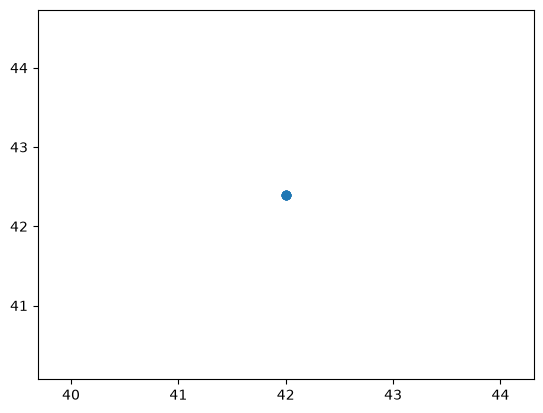

In [3]:
path = "../../Processed_data/"
# path = "../../ZAxisScan/"
# files = glob.glob(f"{path}proc_F_AC_LGAD_40um_strip_NEv*000_BV115000mV_Laser20pc_Temp16C_Zpos*_Xpos*00000.root")
files = glob.glob(f"{path}proc_F_AC_LGAD_40um_strip_10db_attenuation_LaserTuneScan_NEv1000_BV115000mV_Laser*pc_Temp16C_Zpos*_Xpos*_Ypos*00000.root")

# files = glob.glob(f"{path}F*--AC_LGAD_40um_strip_NEv*000_BV115000mV_Laser20pc_Temp16C_Zpos*_Xpos*00000.trc")

Z_range = [] # np.linspace(50.0, 50.8, 11)
X_range = [] # np.linspace(41.4, 41.7, 21)
Y_range = []

map_plot_x = []
map_plot_y = []
map_plot_z = []

for file in files:
    filename = file.split(path)[1]
    print(filename)
    x_pos = float(filename.split("Xpos")[1].split("_")[0])
    y_pos = float(filename.split("Ypos")[1].split("00000.root")[0])
    z_pos = float(filename.split("Zpos")[1].split("_")[0])
    map_plot_x.append(x_pos)
    map_plot_y.append(y_pos)
    map_plot_z.append(z_pos)
    X_range.append(x_pos)
    Y_range.append(y_pos)
    Z_range.append(z_pos)

Z_range = np.unique(Z_range)
X_range = np.unique(X_range)
Y_range = np.unique(Y_range)

# map_plot_x = np.sort(map_plot_x)
# map_plot_z = np.sort(map_plot_z)

plt.scatter(map_plot_x, map_plot_z)
plt.show()

fields = [
    'i_evt',
    # 'channel',
    # 'time',
    # 'baseline',
    'baseline_RMS',
    'noise',
    'amp',
    # 't_peak',
    'integral',
    # 'intfull',
    # 'risetime',
    # 'decaytime',
    # 'LP2_5',
    # 'LP2_10',
    # 'LP2_15',
    # 'LP2_20',
    # 'LP2_25',
    # 'LP2_30',
    # 'LP2_35',
    # 'LP2_40',
    # 'LP2_45',
    'LP2_50',
    # 'LP2_55',
    # 'LP2_60',
    # 'LP2_65',
    # 'LP2_70',
    # 'LP2_75',
    # 'LP2_80',
    # 'LP2_85',
    # 'LP2_90',
    # 'LP2_95',
    # 'LP2_100',
    # 'LP2_10mV',
    # 'LP2_20mV',
    # 'LP2_30mV',
    # 'LP2_50mV',
    # 'LP2_70mV',
    # 'LP2_90mV',
    # 'LP2_100mV',
    # 'LP2_120mV',
    # 'LP2_140mV',
    # 'LP2_160mV',
    # 'LP2_180mV',
    # 'LP2_200mV',
    # 'linear_RE_5',
    # 'linear_RE_10',
    # 'linear_RE_15',
    # 'linear_RE_20',
    # 'linear_RE_25',
    # 'linear_RE_30',
    # 'linear_RE_35',
    # 'linear_RE_40',
    # 'linear_RE_45',
    # 'linear_RE_50',
    # 'linear_RE_55',
    # 'linear_RE_60',
    # 'linear_RE_65',
    # 'linear_RE_70',
    # 'linear_RE_75',
    # 'linear_RE_80',
    # 'linear_RE_85',
    # 'linear_RE_90',
    # 'linear_RE_95',
    # 'linear_RE_100',
    # 'linear_RE__10mV',
    # 'linear_RE__20mV',
    # 'linear_RE__30mV',
    # 'linear_RE__50mV',
    # 'linear_RE__70mV',
    # 'linear_RE__90mV',
    # 'linear_RE__100mV',
    # 'linear_RE__120mV',
    # 'linear_RE__140mV',
    # 'linear_RE__160mV',
    # 'linear_RE__180mV',
    # 'linear_RE__200mV'
]
    